In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
df = pd.read_excel("/Database paper.xlsx", sheet_name="Sheet1")
print("Number of students:", len(df))
print(df[["InfuenceF_Friends", "Time_Friends", "GPA"]].head())


Number of students: 2170
   InfuenceF_Friends  Time_Friends  GPA
0                  3             2    4
1                  4             1    3
2                  4             1    4
3                  4             2    4
4                  5             1    4


In [6]:
counts = df["InfuenceF_Friends"].value_counts().sort_index()
percentages = counts / counts.sum() * 100
summary = pd.DataFrame({"Number of Students": counts,"Percentage": percentages.round(2)})
summary.loc["Total"] = [counts.sum(), 100]
print(summary)
comparison = pd.crosstab(df["InfuenceF_Friends"], df["GPA"])
comparison_percent = pd.crosstab(df["InfuenceF_Friends"], df["GPA"],normalize="index") * 100
print("\nNumber of students:")
print(comparison)
print("\nPercentage of students:")
print(comparison_percent.round(2))


                   Number of Students  Percentage
InfuenceF_Friends                                
1                                  20        0.92
2                                  82        3.78
3                                 707       32.58
4                                 797       36.73
5                                 564       25.99
Total                            2170      100.00

Number of students:
GPA                 1   2    3    4   5
InfuenceF_Friends                      
1                   1   2    8    9   0
2                  14   3   38   17  10
3                  14  36  397  225  35
4                  20  42  438  259  38
5                  24  26  308  182  24

Percentage of students:
GPA                    1      2      3      4      5
InfuenceF_Friends                                   
1                   5.00  10.00  40.00  45.00   0.00
2                  17.07   3.66  46.34  20.73  12.20
3                   1.98   5.09  56.15  31.82   4.95
4        

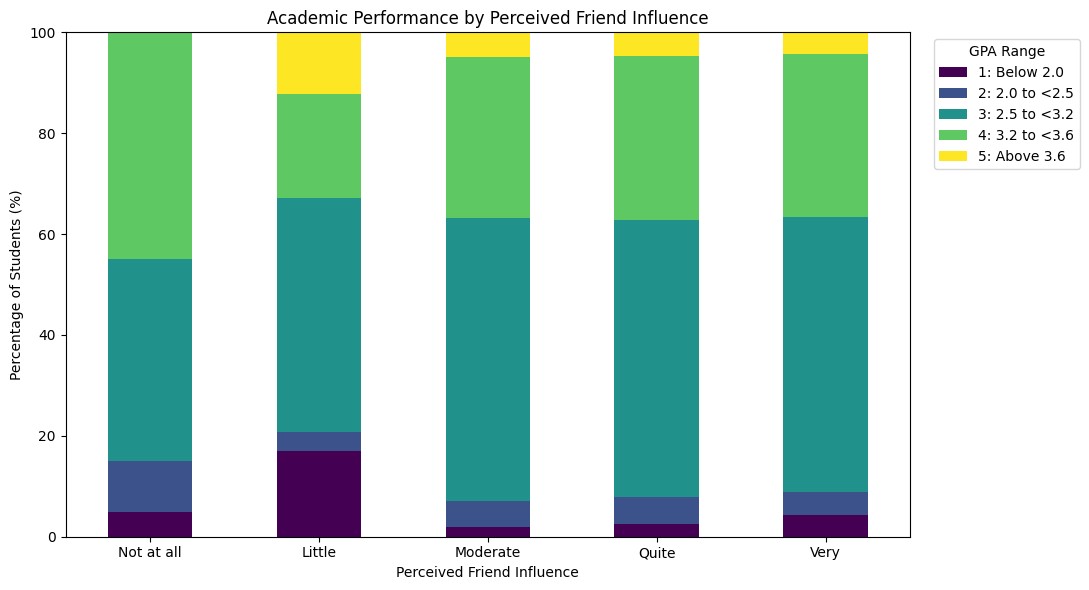

In [7]:

friend_labels = ["Not at all", "Little", "Moderate", "Quite", "Very"]
gpa_labels = ["1: Below 2.0","2: 2.0 to <2.5","3: 2.5 to <3.2","4: 3.2 to <3.6","5: Above 3.6"]
ax = comparison_percent.plot(kind="bar",stacked=True,figsize=(11, 6),colormap="viridis")
plt.title("Academic Performance by Perceived Friend Influence")
plt.xlabel("Perceived Friend Influence")
plt.ylabel("Percentage of Students (%)")
plt.xticks(range(5), friend_labels, rotation=0)
plt.ylim(0, 100)
plt.legend(gpa_labels,title="GPA Range",bbox_to_anchor=(1.02, 1),loc="upper left")
plt.tight_layout()
plt.savefig("friend_influence_gpa.pdf", bbox_inches="tight")
plt.show()


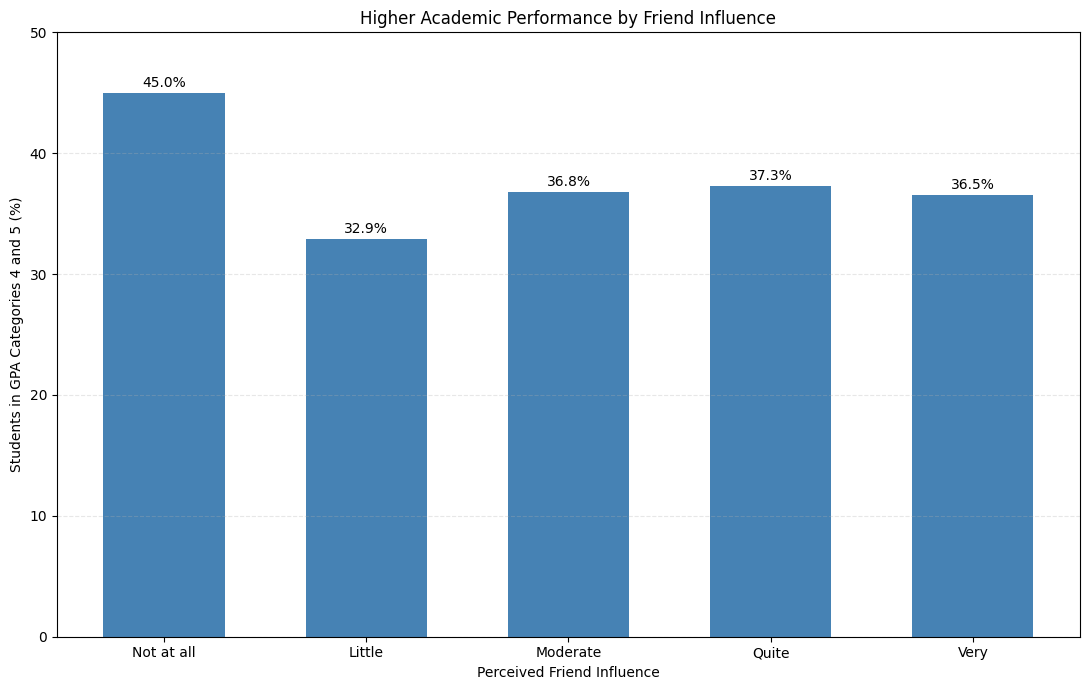

In [8]:
high_gpa = comparison_percent[[4, 5]].sum(axis=1)
plt.figure(figsize=(11, 7))
bars = plt.bar(high_gpa.index.astype(str),high_gpa.values,color="steelblue",width=0.6)
plt.title("Higher Academic Performance by Friend Influence")
plt.xlabel("Perceived Friend Influence")
plt.ylabel("Students in GPA Categories 4 and 5 (%)")
plt.xticks(range(5), friend_labels)
plt.ylim(0, 50)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2,height + 0.5,f"{height:.1f}%",ha="center")

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("high_gpa_friend_influence.pdf")
plt.show()


In [9]:
table = pd.crosstab(df["InfuenceF_Friends"], df["GPA"])
chi2, p_value, dof, expected = chi2_contingency(table)
print("Chi-square statistic:", round(chi2, 3))
print("P-value:", p_value)
print("Degrees of freedom:", dof)
if p_value < 0.05:
    print("Statistically significant association")
else:
    print("No statistically significant association detected")
print("Expected counts below 5:", (expected < 5).sum())
print("Total cells:", expected.size)
n = table.to_numpy().sum()
r, c = table.shape
cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))
print("Cramer's V:", round(cramers_v, 3))


Chi-square statistic: 71.481
P-value: 5.483820324884056e-09
Degrees of freedom: 16
Statistically significant association
Expected counts below 5: 6
Total cells: 25
Cramer's V: 0.091


In [14]:
data = df[["InfuenceF_Friends", "Time_Friends", "GPA"]].dropna().copy()
data["High_GPA"] = data["GPA"].isin([4, 5])
result = data.groupby(["InfuenceF_Friends", "Time_Friends"])["High_GPA"].agg(students="count",percentage="mean")
result["percentage"] = result["percentage"] * 100
print(result.round(2))


                                students  percentage
InfuenceF_Friends Time_Friends                      
1                 1                    1        0.00
                  2                    9       55.56
                  3                    7       42.86
                  4                    1        0.00
                  5                    2       50.00
2                 1                   15       46.67
                  2                   23       26.09
                  3                   31       25.81
                  4                   12       50.00
                  5                    1        0.00
3                 1                  154       35.71
                  2                  263       36.50
                  3                  199       39.70
                  4                   57       36.84
                  5                   34       26.47
4                 1                  238       39.92
                  2                  286      

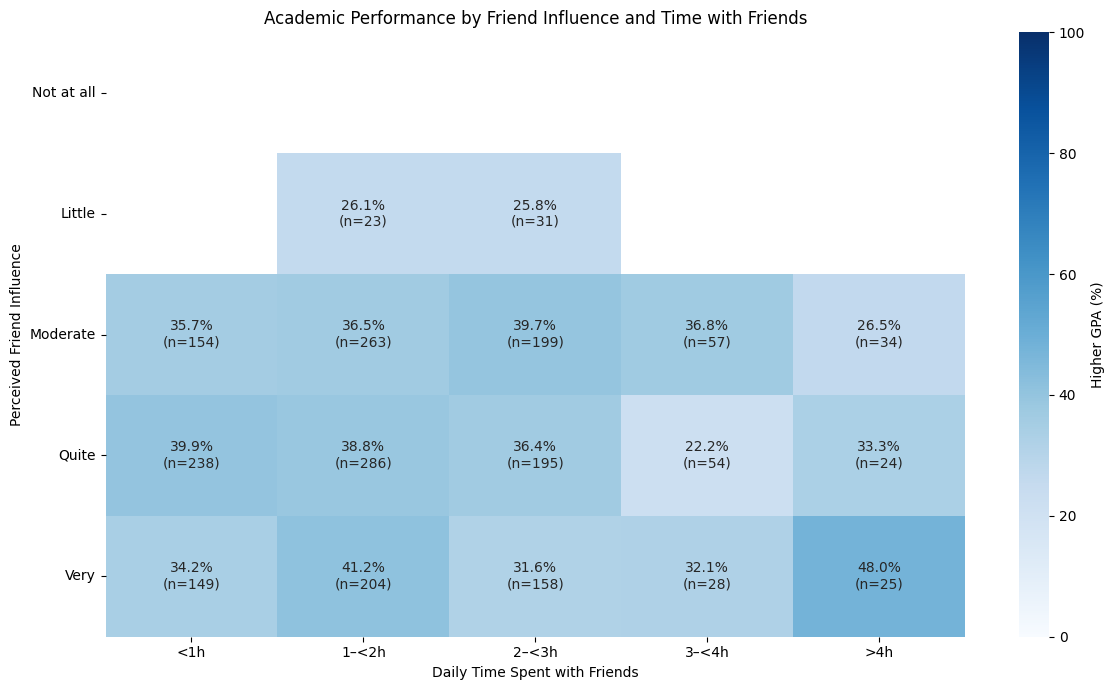

In [11]:
heatmap_data = result["percentage"].unstack()
sample_sizes = result["students"].unstack()
heatmap_data = heatmap_data.mask(sample_sizes < 20)
labels = heatmap_data.copy().astype(object)
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        value = heatmap_data.iloc[i, j]
        n = sample_sizes.iloc[i, j]
        if pd.notna(value):
            labels.iloc[i, j] = f"{value:.1f}%\n(n={int(n)})"
        else:
            labels.iloc[i, j] = ""
plt.figure(figsize=(12, 7))
sns.heatmap(heatmap_data,annot=labels,fmt="",cmap="Blues",vmin=0,vmax=100,cbar_kws={"label": "Higher GPA (%)"})
plt.title("Academic Performance by Friend Influence and Time with Friends")
plt.xlabel("Daily Time Spent with Friends")
plt.ylabel("Perceived Friend Influence")
plt.xticks(np.arange(5) + 0.5,["<1h", "1–<2h", "2–<3h", "3–<4h", ">4h"],rotation=0)
plt.yticks(np.arange(5) + 0.5,friend_labels,rotation=0)
plt.tight_layout()
plt.savefig("three_variable_heatmap.pdf", bbox_inches="tight")
plt.show()


In [13]:
test_data = df[["InfuenceF_Friends", "GPA"]].dropna()
original_table = pd.crosstab(test_data["InfuenceF_Friends"], test_data["GPA"])
observed = chi2_contingency(original_table)[0]
gpa = test_data["GPA"].to_numpy().copy()
random = np.random.default_rng(42)
simulated = []
for i in range(2000):
    random.shuffle(gpa)
    shuffled_table = pd.crosstab(test_data["InfuenceF_Friends"], gpa)
    simulated.append(chi2_contingency(shuffled_table)[0])
p_permutation = (sum(x >= observed for x in simulated) + 1) / 2001
print("Permutation p-value:", p_permutation)


Permutation p-value: 0.0004997501249375312


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>